In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('loan_approved.csv')
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


### 1) Basic Checks

In [3]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [5]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='str')

In [6]:
# pd.set_option('display.max_rows'.none)
# df         (to get all rows)

In [7]:
df = df.rename(columns= {'Loan_Status (Approved)':'Loan_Status'})
#  df.rename(columns= {'Loan_Status (Approved)':'Loan_Status'}, inplace = True)


In [8]:
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [10]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [11]:
df.describe(include = 'O')

C:\Users\Admin\AppData\Local\Temp\ipykernel_7436\3536098803.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include = 'O')


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


In [12]:
df.Gender.unique()

<ArrowStringArray>
['Male', 'Female', nan]
Length: 3, dtype: str

In [13]:
df.Gender.value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [14]:
df.Gender.dtype

<StringDtype(na_value=nan)>

In [15]:
len (df.Gender.unique())

3

In [16]:
for i in df:
    print(i)

Loan_ID
Gender
Married
Dependents
Education
Self_Employed
ApplicantIncome
CoapplicantIncome
LoanAmount
Loan_Amount_Term
Credit_History
Property_Area
Loan_Status


In [17]:
for i in df:
    if len(df[i].unique()) <=20:
        print(i, ':', df[i].unique())

Gender : <ArrowStringArray>
['Male', 'Female', nan]
Length: 3, dtype: str
Married : <ArrowStringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
Dependents : <ArrowStringArray>
['0', '1', '2', '3+', nan]
Length: 5, dtype: str
Education : <ArrowStringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str
Self_Employed : <ArrowStringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
Loan_Amount_Term : [360. 120. 240.  nan 180.  60. 300. 480.  36.  84.  12.]
Credit_History : [ 1.  0. nan]
Property_Area : <ArrowStringArray>
['Urban', 'Rural', 'Semiurban']
Length: 3, dtype: str
Loan_Status : <ArrowStringArray>
['Y', 'N']
Length: 2, dtype: str


In [18]:
for i in df:
    if len(df[i].unique()) <=20:
        print(df[i].value_counts())
        print('==============================================')

Gender
Male      489
Female    112
Name: count, dtype: int64
Married
Yes    398
No     213
Name: count, dtype: int64
Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64
Self_Employed
No     500
Yes     82
Name: count, dtype: int64
Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64
Credit_History
1.0    475
0.0     89
Name: count, dtype: int64
Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64
Loan_Status
Y    422
N    192
Name: count, dtype: int64


## EDA 

### Univariate analysis

In [19]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


<Axes: xlabel='Gender', ylabel='count'>

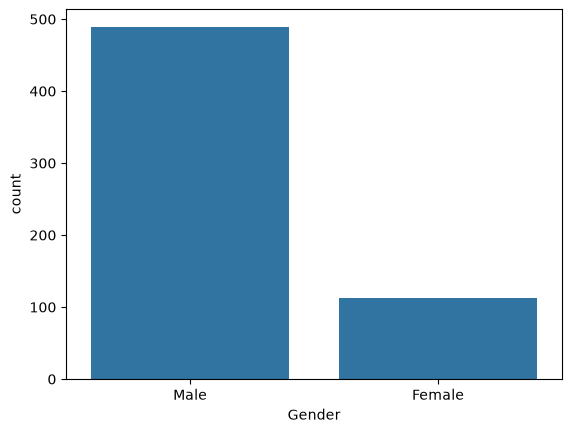

In [20]:
sns.countplot(x = df.Gender)

In [21]:
categorical = []
for i in df:
    if len(df[i].unique()) <=20:
        categorical.append(i)

In [22]:
categorical

['Gender',
 'Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'Loan_Amount_Term',
 'Credit_History',
 'Property_Area',
 'Loan_Status']

In [23]:
df_cat = df[categorical]
df_cat.head()

,Gender,Married,Dependents,Education,Self_Employed,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,360.0,1.0,Urban,Y


In [24]:
continuous = []
for i in df:
    if len(df[i].unique()) >=20:
        continuous.append(i)

In [25]:
continuous

['Loan_ID', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']

In [26]:
df_cont = df[continuous]
df_cont.head()

,Loan_ID,ApplicantIncome,CoapplicantIncome,LoanAmount
0,LP001002,5849,0.0,NaN
1,LP001003,4583,1508.0,128.0
2,LP001005,3000,0.0,66.0
3,LP001006,2583,2358.0,120.0
4,LP001008,6000,0.0,141.0


In [27]:
df_cont = df_cont.drop(columns = 'Loan_ID')
df_cont.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount
0,5849,0.0,NaN
1,4583,1508.0,128.0
2,3000,0.0,66.0
3,2583,2358.0,120.0
4,6000,0.0,141.0


In [28]:
df_cat.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

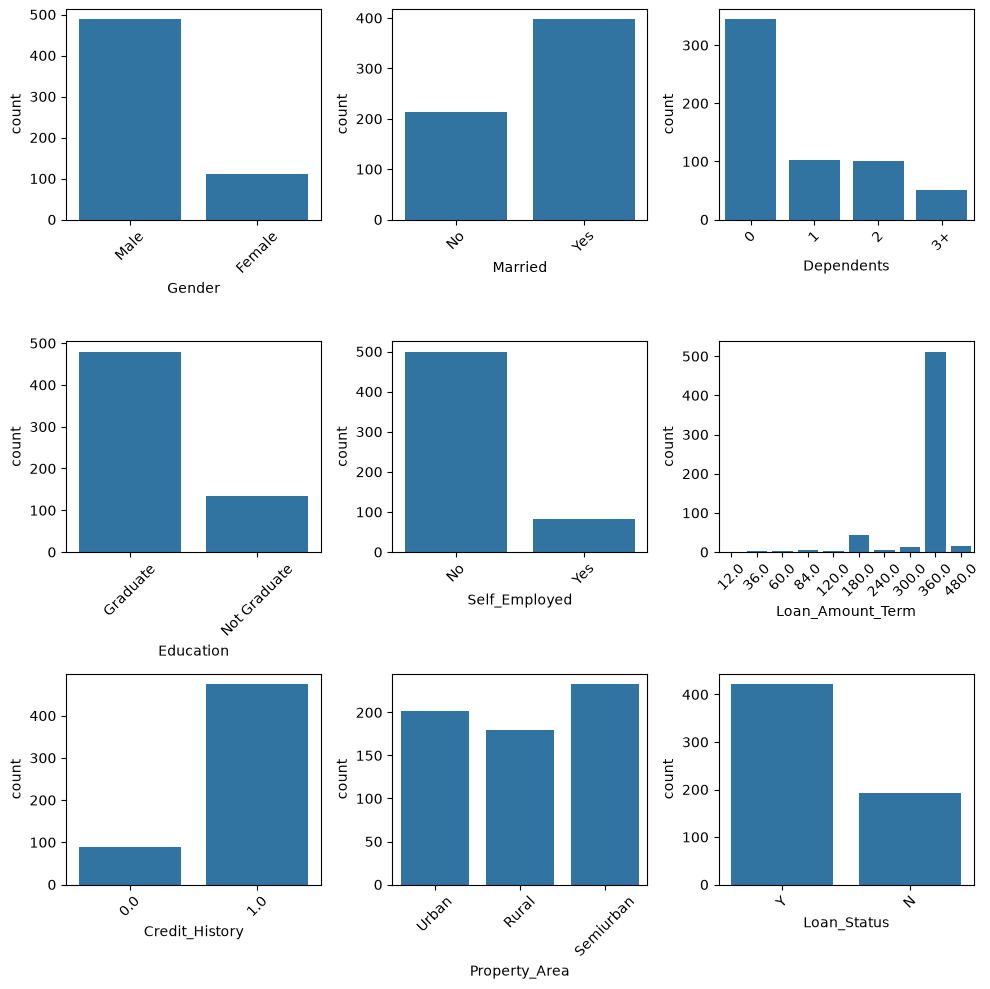

In [29]:
plotnumber = 1
plt.figure(figsize=(10,10))
for i in df_cat:
    plt.subplot(3,3,plotnumber)
    sns.countplot(x = df_cat[i])
    plt.xticks(rotation=45)
    plotnumber = plotnumber+1
    plt.tight_layout()

In [30]:
df_cont.columns

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount'], dtype='str')

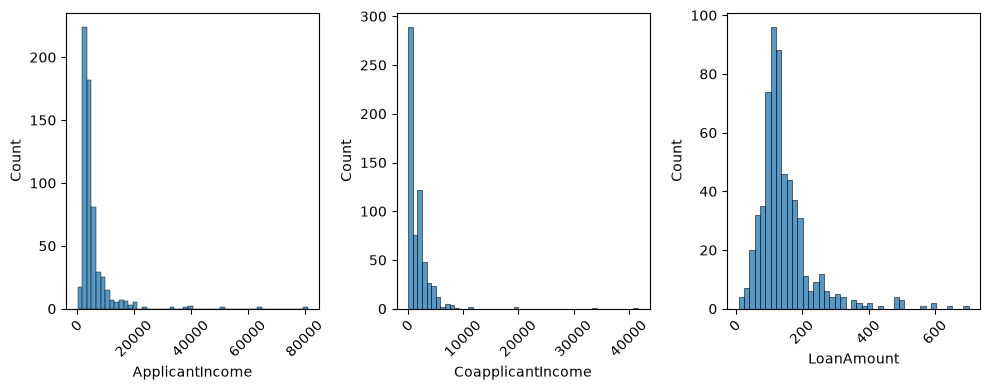

In [31]:
plotnumber = 1
plt.figure(figsize=(10,4))
for i in df_cont:
    plt.subplot(1,3,plotnumber)
    sns.histplot(x = df_cont[i])
    plt.xticks(rotation=45)
    plotnumber = plotnumber+1
    plt.tight_layout()

### Bivariate Analysis

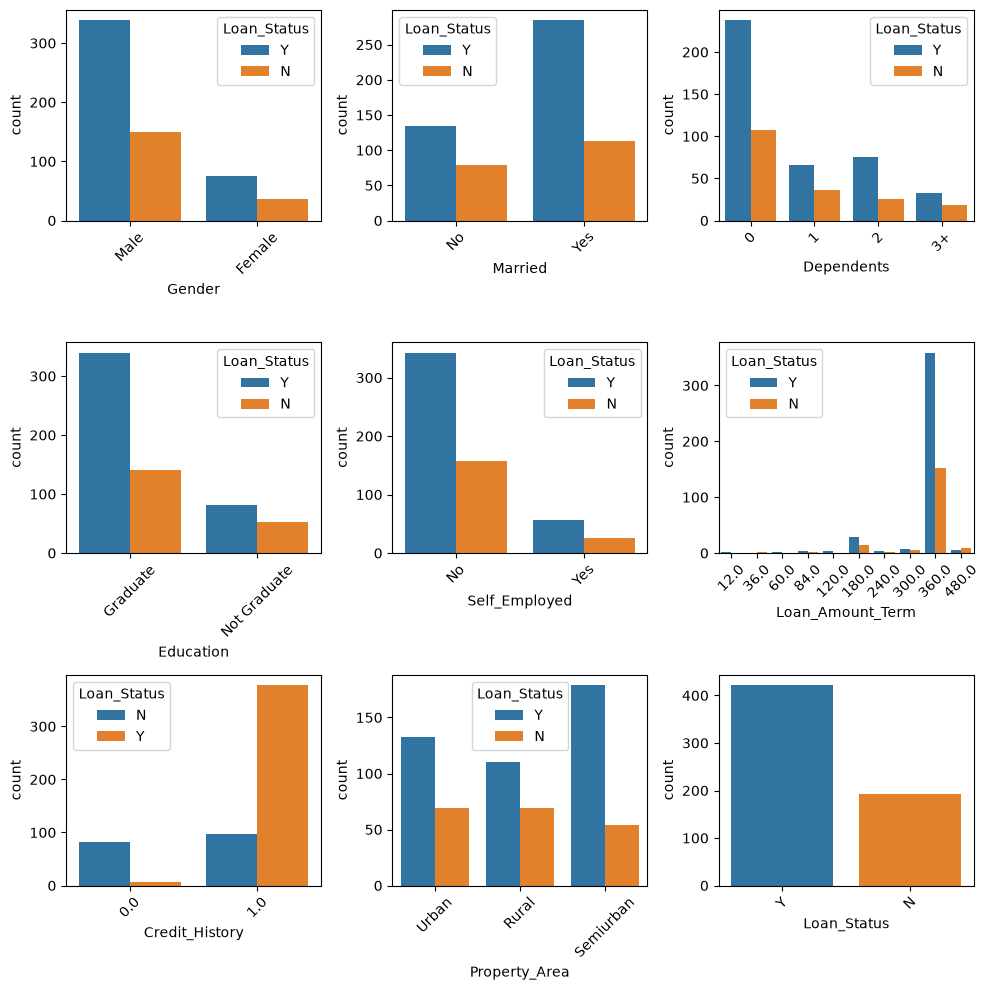

In [32]:
plotnumber = 1
plt.figure(figsize=(10,10))
for i in df_cat:
    plt.subplot(3,3,plotnumber)
    sns.countplot(x = df_cat[i],hue = df.Loan_Status)
    plt.xticks(rotation=45)
    plotnumber = plotnumber+1
    plt.tight_layout()


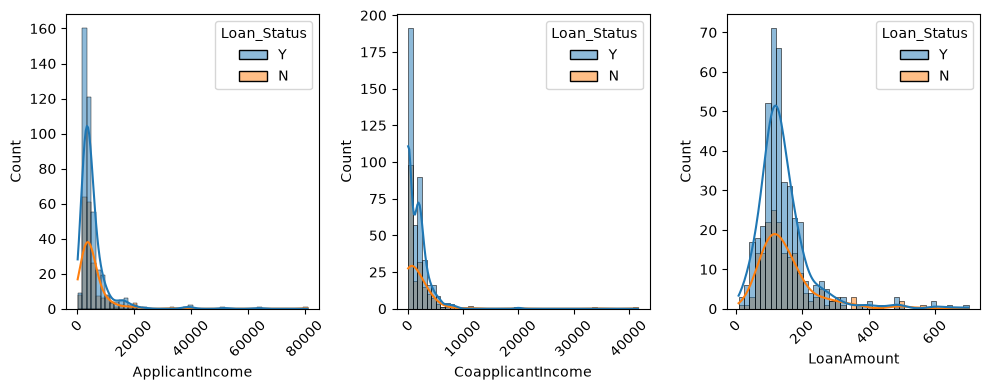

In [33]:
plotnumber = 1
plt.figure(figsize=(10,4))
for i in df_cont:
    plt.subplot(1,3,plotnumber)
    sns.histplot(x = df_cont[i],hue = df.Loan_Status,kde= True)
    plt.xticks(rotation=45)
    plotnumber = plotnumber+1
    plt.tight_layout()

### Data Cleeaning

### 1)Handelinng with null values

In [34]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [35]:
df.loc[df.Gender.isnull()]

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
23,LP001050,NaN,Yes,2,Not Graduate,No,3365,1917.0,112.0,360.0,0.0,Rural,N
126,LP001448,NaN,Yes,3+,Graduate,No,23803,0.0,370.0,360.0,1.0,Rural,Y
171,LP001585,NaN,Yes,3+,Graduate,No,51763,0.0,700.0,300.0,1.0,Urban,Y
188,LP001644,NaN,Yes,0,Graduate,Yes,674,5296.0,168.0,360.0,1.0,Rural,Y
314,LP002024,NaN,Yes,0,Graduate,No,2473,1843.0,159.0,360.0,1.0,Rural,N
334,LP002103,NaN,Yes,1,Graduate,Yes,9833,1833.0,182.0,180.0,1.0,Urban,Y
460,LP002478,NaN,Yes,0,Graduate,Yes,2083,4083.0,160.0,360.0,NaN,Semiurban,Y
467,LP002501,NaN,Yes,0,Graduate,No,16692,0.0,110.0,360.0,1.0,Semiurban,Y
477,LP002530,NaN,Yes,2,Graduate,No,2873,1872.0,132.0,360.0,0.0,Semiurban,N
507,LP002625,NaN,No,0,Graduate,No,3583,0.0,96.0,360.0,1.0,Urban,N


In [36]:
df.loc[df.Gender.isnull(),'Gender']

23     NaN
126    NaN
171    NaN
188    NaN
314    NaN
334    NaN
460    NaN
467    NaN
477    NaN
507    NaN
576    NaN
588    NaN
592    NaN
Name: Gender, dtype: str

In [37]:
df.Gender.value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [38]:
df.loc[df.Gender.isnull(),'Gender'] = 'Male'

#or

#df.Geender=df.Gender.fillana(value='Male')

In [39]:
df.Gender.isnull().sum()

np.int64(0)

In [40]:
df.Married.value_counts()

Married
Yes    398
No     213
Name: count, dtype: int64

In [41]:
df.loc[df.Married.isnull(),'Married'] = 'Yes'

In [42]:
df.Married.isnull().sum()

np.int64(0)

In [43]:
df.Married.unique()

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

In [44]:
df.loc[df.Dependents.isnull()]

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
102,LP001350,Male,Yes,NaN,Graduate,No,13650,0.0,NaN,360.0,1.0,Urban,Y
104,LP001357,Male,Yes,NaN,Graduate,No,3816,754.0,160.0,360.0,1.0,Urban,Y
120,LP001426,Male,Yes,NaN,Graduate,No,5667,2667.0,180.0,360.0,1.0,Rural,Y
226,LP001754,Male,Yes,NaN,Not Graduate,Yes,4735,0.0,138.0,360.0,1.0,Urban,N
228,LP001760,Male,Yes,NaN,Graduate,No,4758,0.0,158.0,480.0,1.0,Semiurban,Y
293,LP001945,Female,No,NaN,Graduate,No,5417,0.0,143.0,480.0,0.0,Urban,N
301,LP001972,Male,Yes,NaN,Not Graduate,No,2875,1750.0,105.0,360.0,1.0,Semiurban,Y
332,LP002100,Male,No,NaN,Graduate,No,2833,0.0,71.0,360.0,1.0,Urban,Y
335,LP002106,Male,Yes,NaN,Graduate,Yes,5503,4490.0,70.0,NaN,1.0,Semiurban,Y
346,LP002130,Male,Yes,NaN,Not Graduate,No,3523,3230.0,152.0,360.0,0.0,Rural,N


In [45]:
df.Dependents.value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [46]:
df.loc[df.Dependents.isnull(),'Dependents']= '0'     

In [47]:
df.Dependents.isnull().sum()

np.int64(0)

In [48]:
df.Dependents.unique()

<ArrowStringArray>
['0', '1', '2', '3+']
Length: 4, dtype: str

In [49]:
df.loc[df.Self_Employed.isnull(),'Self_Employed']

11     NaN
19     NaN
24     NaN
29     NaN
30     NaN
95     NaN
107    NaN
111    NaN
114    NaN
158    NaN
170    NaN
218    NaN
231    NaN
236    NaN
268    NaN
295    NaN
333    NaN
336    NaN
344    NaN
374    NaN
380    NaN
385    NaN
411    NaN
432    NaN
447    NaN
463    NaN
468    NaN
535    NaN
542    NaN
579    NaN
600    NaN
601    NaN
Name: Self_Employed, dtype: str

In [50]:
df.Self_Employed.value_counts()

Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [51]:
df.loc[df.Self_Employed.isnull(),'Self_Employed'] = 'No'

In [52]:
df.Self_Employed.isnull().sum()

np.int64(0)

In [53]:
df.loc[df.LoanAmount.isnull()]

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
35,LP001106,Male,Yes,0,Graduate,No,2275,2067.0,NaN,360.0,1.0,Urban,Y
63,LP001213,Male,Yes,1,Graduate,No,4945,0.0,NaN,360.0,0.0,Rural,N
81,LP001266,Male,Yes,1,Graduate,Yes,2395,0.0,NaN,360.0,1.0,Semiurban,Y
95,LP001326,Male,No,0,Graduate,No,6782,0.0,NaN,360.0,NaN,Urban,N
102,LP001350,Male,Yes,0,Graduate,No,13650,0.0,NaN,360.0,1.0,Urban,Y
103,LP001356,Male,Yes,0,Graduate,No,4652,3583.0,NaN,360.0,1.0,Semiurban,Y
113,LP001392,Female,No,1,Graduate,Yes,7451,0.0,NaN,360.0,1.0,Semiurban,Y
127,LP001449,Male,No,0,Graduate,No,3865,1640.0,NaN,360.0,1.0,Rural,Y
202,LP001682,Male,Yes,3+,Not Graduate,No,3992,0.0,NaN,180.0,1.0,Urban,N


In [54]:
df.LoanAmount

0        NaN
1      128.0
2       66.0
3      120.0
4      141.0
       ...  
609     71.0
610     40.0
611    253.0
612    187.0
613    133.0
Name: LoanAmount, Length: 614, dtype: float64

In [55]:
df.LoanAmount.dropna()

1      128.0
2       66.0
3      120.0
4      141.0
5      267.0
       ...  
609     71.0
610     40.0
611    253.0
612    187.0
613    133.0
Name: LoanAmount, Length: 592, dtype: float64

In [56]:
np.median(df.LoanAmount.dropna())

np.float64(128.0)

In [57]:
df.loc[df.LoanAmount.isnull(),'LoanAmount'] = np.median(df.LoanAmount.dropna())

In [58]:
df.LoanAmount.isnull().sum()

np.int64(0)

In [59]:
df.Loan_Amount_Term

0      360.0
1      360.0
2      360.0
3      360.0
4      360.0
       ...  
609    360.0
610    180.0
611    360.0
612    360.0
613    360.0
Name: Loan_Amount_Term, Length: 614, dtype: float64

In [60]:
df.Loan_Amount_Term.value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [61]:
df.loc[df.Loan_Amount_Term.isnull(),'Loan_Amount_Term'] = 360.0

In [62]:
df.Loan_Amount_Term.isnull().sum()

np.int64(0)

In [63]:
df.Credit_History.value_counts()

Credit_History
1.0    475
0.0     89
Name: count, dtype: int64

In [64]:
df.loc[df.Credit_History.isnull(),'Credit_History'] = 1.0

In [65]:
df.Credit_History.unique()

array([1., 0.])

In [66]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

### 2) remove duplicates

### 3)correct datatypes

### 4)standardizer text

### 5) fix spelling errors

### 6) handle outliers

<Axes: xlabel='ApplicantIncome'>

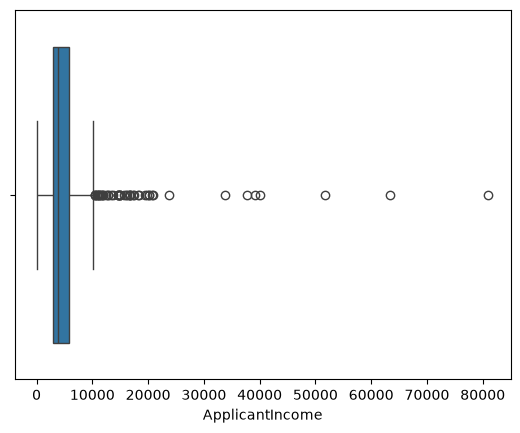

In [68]:
sns.boxplot(x = df.ApplicantIncome)     #handle outliers by draw boxplot and normal distribution

### 7) remove unwanted data(columns/rows)

### 8)standardize dates(keeping same format)

### 9)hanndle inconsistant units (converting to common units)

## Exporting Data

In [71]:
df.to_csv('loan_approved_clean.csv')